# Binario (nevus vs others): ML con grid search, ensembles y umbral — elegido por ACCURACY

Basado en `ml_accuracy_features_final.ipynb` (mismas features, mismo pipeline, mismos folds). Lo nuevo, todo pensado
para maximizar la **accuracy** (la métrica con la que nos evalúan en binario):

- **4b. Grid search** de los hiperparámetros de cada modelo (profundidad, nº de árboles / iteraciones, learning rate,
  C, vecinos...) con la misma CV de 5 folds y el mismo pipeline. Los mejores sustituyen a los de `MODELS`.
- **6b. Ensembles** (media de probabilidades) de los mejores modelos, comparados por CV como uno más.
- **6c. Umbral de decisión**: el umbral que maximiza la accuracy, elegido con las predicciones out-of-fold de la CV
  (no con val) y comprobado en val.
- **9. Modelo final para el test**, reentrenado con train + val.

Orden del notebook:
1. Carga de `features_train.csv` / `features_val.csv` (busca `features_binary_final/` o `features_final/`).
2. **Árbol de decisión** para ver qué features son más útiles (y si esa lista es estable entre folds).
3. Selección de las top-K features, **dentro de cada fold** de la validación cruzada.
4. Baseline (regresión logística) y otros modelos, con **todas** las features y con las **top-K**, con los
   hiperparámetros ajustados en 4b.
5. Ablación por familias.
6. Evaluación final en **val** (+ ensembles y umbral).
7-8. Guardado, importancia por permutación y controles.
9. Modelo final con train + val.

Etiqueta: `label` (nevus = 0, others = 1). Se excluyen `name`, `class`, `subtype` (delata la clase) y `qc_*`.

In [1]:
import os
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

try:
    from xgboost import XGBClassifier
except Exception as e:      # ImportError, o versiones mezcladas de conda/pip (ValueError)
    import sys
    XGBClassifier = None
    print(f"AVISO: no se puede importar xgboost -> se omite XGBoost\n"
          f"  error: {type(e).__name__}: {e}\n  python del kernel: {sys.executable}")

warnings.filterwarnings("ignore")

# ---------------- Configuración ----------------
# raíz del proyecto: la carpeta que contiene Binary/, buscando desde la carpeta del notebook hacia arriba
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Binary").is_dir()), Path.cwd())
# ROOT = Path(r"C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG")    # o fíjala a mano
FEAT_DIR = next((ROOT / d for d in ("features_binary_final", "features_binary_final")
                 if (ROOT / d / "features_train.csv").exists()), None)
assert FEAT_DIR is not None, f"No encuentro features_binary_final/ ni features_binary_final/ con features_train.csv en {ROOT}"
TRAIN_CSV = FEAT_DIR / "features_train.csv"
VAL_CSV   = FEAT_DIR / "features_val.csv"
OUT_DIR   = ROOT / "ml" / "ml_results_binary_gridsearch"      # carpeta propia: no pisa otros resultados

K_FEATURES = 30
CV_FOLDS = 5
SEED = 42
N_JOBS = max(1, (os.cpu_count() or 1) - 2)          # todos los cores disponibles menos 2
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"ROOT: {ROOT}\nfeatures: {FEAT_DIR}\ncores: {os.cpu_count()} -> N_JOBS = {N_JOBS}")

ROOT: C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG
features: C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG\features_binary_final
cores: 28 -> N_JOBS = 26


## 1. Carga de datos

In [2]:
tr, va = pd.read_csv(TRAIN_CSV), pd.read_csv(VAL_CSV)

PREFIXES = ("shape_", "color_", "tex_", "gcolor_", "gtex_")
FEATS = [c for c in tr.columns if c.startswith(PREFIXES)]
assert FEATS == [c for c in va.columns if c.startswith(PREFIXES)], "train y val tienen columnas distintas"

Xtr, ytr = tr[FEATS].replace([np.inf, -np.inf], np.nan), tr["label"].values
Xva, yva = va[FEATS].replace([np.inf, -np.inf], np.nan), va["label"].values
family = lambda c: c.split("_")[0]

print(f"train: {Xtr.shape}  (others = {ytr.mean():.1%})   val: {Xva.shape}  (others = {yva.mean():.1%})")
print("features por familia:", pd.Series([family(c) for c in FEATS]).value_counts().to_dict())
print("NaN en features: train", int(Xtr.isna().sum().sum()), "| val", int(Xva.isna().sum().sum()))

skf = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
FAM_COLOR = {"shape": "#1f77b4", "color": "#d62728", "tex": "#2ca02c",
             "gcolor": "#ff9896", "gtex": "#98df8a"}

train: (15195, 412)  (others = 49.2%)   val: (3796, 412)  (others = 49.1%)
features por familia: {'tex': 104, 'gtex': 104, 'color': 82, 'gcolor': 70, 'shape': 52}
NaN en features: train 0 | val 0


## 2. Árbol de decisión: ¿qué features son más útiles?

Un árbol poco profundo (`max_depth=5`) es fácil de interpretar. Su importancia de cada feature es la reducción
total de impureza (Gini) que consigue al dividir con ella.
Aviso: **un solo árbol es inestable** (cambia bastante según los datos), por eso también miramos si el ranking
se repite en cada fold.

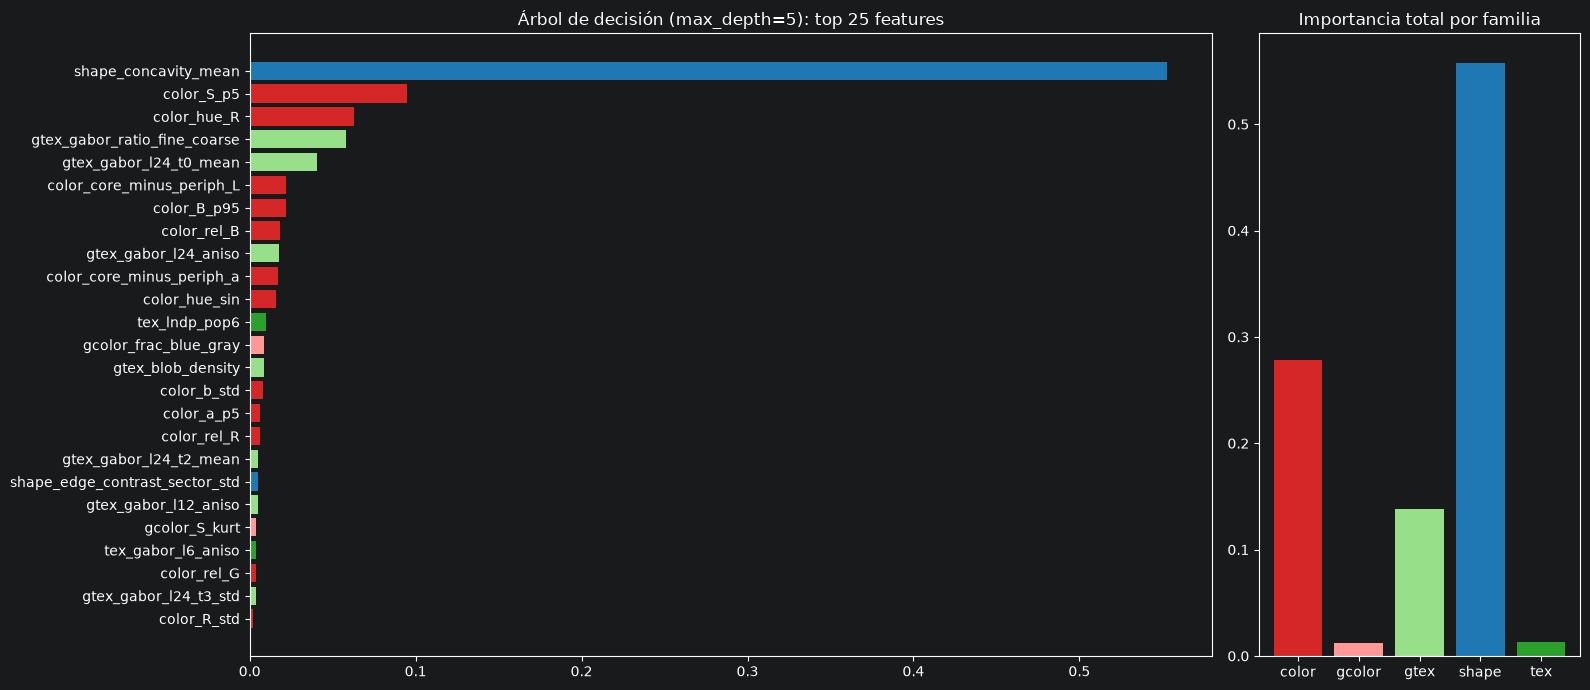

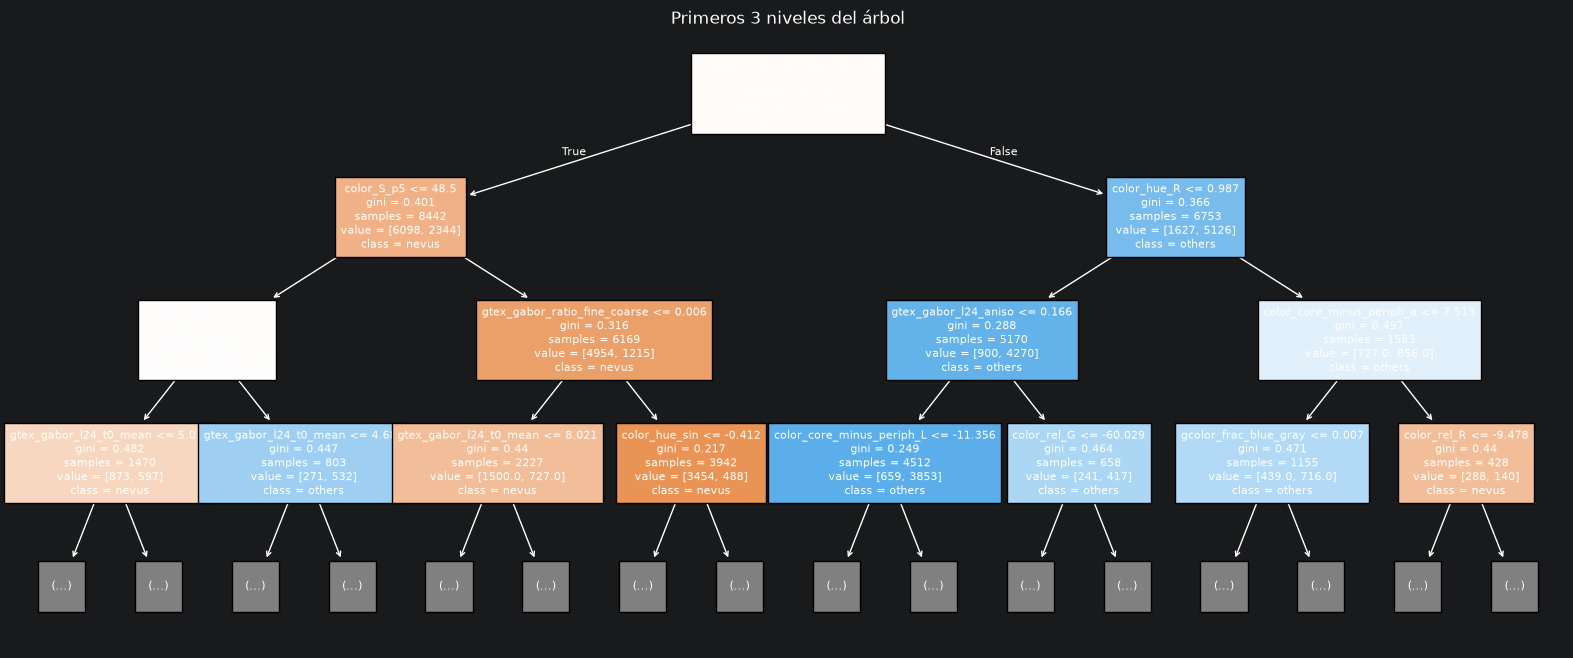

In [3]:
imp = SimpleImputer(strategy="median").fit(Xtr)
Xtr_i = pd.DataFrame(imp.transform(Xtr), columns=FEATS)

tree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED).fit(Xtr_i, ytr)
imp_tree = pd.Series(tree.feature_importances_, index=FEATS).sort_values(ascending=False)

fig, axs = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [3, 1]})
top = imp_tree.head(25)[::-1]
axs[0].barh(top.index, top.values, color=[FAM_COLOR[family(c)] for c in top.index])
axs[0].set_title("Árbol de decisión (max_depth=5): top 25 features")
fam_imp = imp_tree.groupby(lambda c: family(c)).sum()
axs[1].bar(fam_imp.index, fam_imp.values, color=[FAM_COLOR[f] for f in fam_imp.index])
axs[1].set_title("Importancia total por familia")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tree, max_depth=3, feature_names=FEATS, class_names=["nevus", "others"], filled=True, fontsize=8, ax=ax)
ax.set_title("Primeros 3 niveles del árbol")
plt.show()

### Estabilidad del ranking entre folds
Se entrena un árbol en cada fold (solo con sus datos de entrenamiento). Una feature útil de verdad debería
aparecer arriba en casi todos los folds.

In [4]:
def _tree_fold(X, y, a, b):
    t = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED).fit(X[a], y[a])
    return t.feature_importances_, roc_auc_score(y[b], t.predict_proba(X[b])[:, 1])


Xtr_i_np = Xtr_i.to_numpy()
out = Parallel(n_jobs=N_JOBS)(delayed(_tree_fold)(Xtr_i_np, ytr, a, b) for a, b in skf.split(Xtr_i_np, ytr))
imp_cv = pd.DataFrame([o[0] for o in out], columns=FEATS)
aucs = [o[1] for o in out]
stab = pd.DataFrame({"importancia_media": imp_cv.mean(), "importancia_std": imp_cv.std(),
                     "folds_en_top15": (imp_cv.rank(axis=1, ascending=False) <= 15).sum()})
print(f"AUC del árbol solo (CV {CV_FOLDS} folds): {np.mean(aucs):.3f} ± {np.std(aucs):.3f}\n")
print(stab.sort_values("importancia_media", ascending=False).head(20).round(3).to_string())

AUC del árbol solo (CV 5 folds): 0.843 ± 0.003

                              importancia_media  importancia_std  folds_en_top15
shape_concavity_mean                      0.434            0.243               4
shape_solidity                            0.106            0.234               1
color_hue_R                               0.075            0.021               5
color_S_p5                                0.060            0.034               4
gtex_gabor_ratio_fine_coarse              0.048            0.012               5
color_rel_B                               0.036            0.010               5
color_B_p95                               0.025            0.040               2
color_core_minus_periph_a                 0.021            0.014               4
gtex_gabor_l24_t0_mean                    0.018            0.011               4
color_core_minus_periph_L                 0.013            0.008               4
color_b_std                               0.012            0.

## 3. Selección de las top-K features con Random Forest

Un árbol suelto es inestable y, con features correlacionadas, elige una y deja a 0 las demás. Por eso el selector
es un **Random Forest** (300 árboles, `max_features="sqrt"`: en cada split solo se mira un subconjunto aleatorio de
features, así las correlacionadas se reparten la importancia y el ranking es más estable). Con
`SelectFromModel(..., max_features=K, threshold=-np.inf)` se queda exactamente con las K de mayor importancia.

Va **dentro del pipeline**, así en validación cruzada se recalcula con los datos de entrenamiento de cada fold y nunca
ve el fold de validación. (Para ir más rápido se puede cambiar por `ExtraTreesClassifier`, está comentado en `make_selector`.)

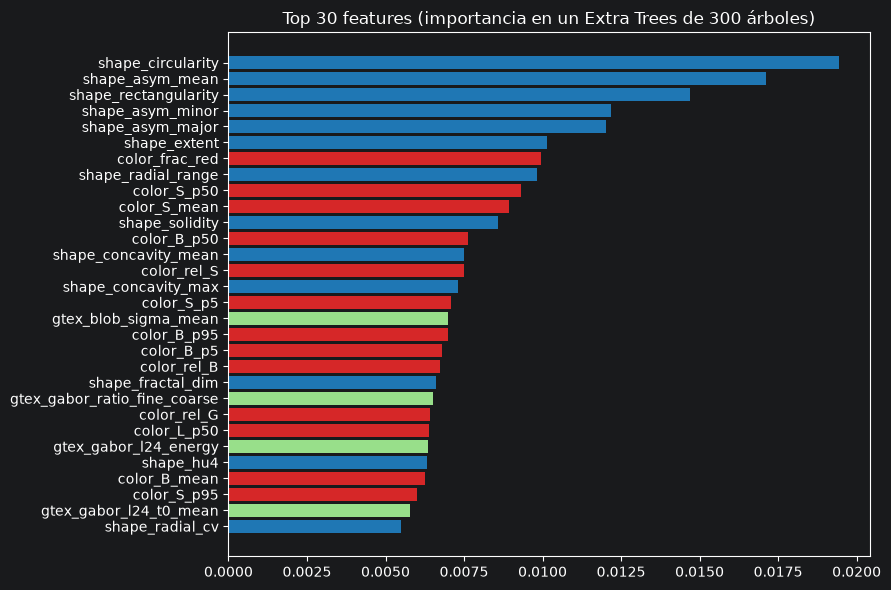

Familias en el top: {'shape': 13, 'color': 13, 'gtex': 4}


In [5]:
def make_selector(k, n_jobs=1):
    """Top-k features según la importancia (Gini) de un Extra Trees."""
    est = ExtraTreesClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=3,
                               random_state=SEED, n_jobs=n_jobs)          # ~5x más rápido que RandomForest
    # est = RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=3,
    #                              random_state=SEED, n_jobs=n_jobs)      # versión anterior (más lenta)
    return SelectFromModel(est, max_features=k, threshold=-np.inf)


# lista de features elegidas con all train (solo para mostrarla; la CV lo hace dentro de cada fold)
selector = make_selector(K_FEATURES, n_jobs=N_JOBS).fit(Xtr_i, ytr)
sel_imp = pd.Series(selector.estimator_.feature_importances_, index=FEATS).sort_values(ascending=False)
SELECTED = list(sel_imp.index[:K_FEATURES])
sel_imp.head(K_FEATURES).rename("importancia").to_csv(OUT_DIR / "selected_features.csv")

top = sel_imp.head(K_FEATURES)[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values, color=[FAM_COLOR[family(c)] for c in top.index])
plt.title(f"Top {K_FEATURES} features (importancia en un Extra Trees de 300 árboles)")
plt.tight_layout(); plt.show()
print("Familias en el top:", pd.Series([family(c) for c in SELECTED]).value_counts().to_dict())

## 4. Baseline y otros modelos

- **Imputación** (mediana) → **selección top-K** (opcional) → **transformación cuantil a normal** (solo en modelos que
  la necesitan; las features tienen colas muy pesadas) → modelo.
- **Baseline**: regresión logística. `Dummy` es el suelo (AUC 0.5). Modelos: LogReg, KNN, SVM-RBF, árbol, Random Forest,
  HistGradientBoosting y **XGBoost** (si está instalado).
- Métricas en CV: **accuracy** (la que nos evalúan; es el criterio para elegir el mejor modelo), AUC, balanced accuracy, F1 y **recall de `others`** (clase positiva = 1).
- Los hiperparámetros de `MODELS` son el punto de partida: el **grid search (4b)** los sustituye por los mejores
  por accuracy antes de la CV.

**Paralelización** (`N_JOBS` = cores − 2). Es la misma CV de antes (mismos folds y mismo pipeline), organizada para no repetir trabajo:
1. La imputación y la selección top-K se ajustan **una vez por fold** (solo con el train del fold) y se reutilizan
   en todos los modelos; antes se repetían para cada modelo, aunque salían idénticas.
2. Todos los pares **modelo × fold** se entrenan a la vez, repartidos entre los cores. Cada modelo usa 1 core
   (`n_jobs=1`) para no pisarse con el paralelismo de fuera.

In [6]:
MODELS = {   # nombre: (estimador, ¿necesita escalado?)
    "Dummy": (DummyClassifier(strategy="prior"), False),
    "LogReg (baseline)": (LogisticRegression(C=0.5, max_iter=3000), True),
    "KNN": (KNeighborsClassifier(n_neighbors=15), True),
    "SVM-RBF": (SVC(C=1.0, gamma="scale"), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED), False),
    "Random Forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=1), False),
    "HistGradientBoosting": (HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_depth=4,
                                                           early_stopping=False, random_state=SEED), False),
}
if XGBClassifier is not None:
    MODELS["XGBoost"] = (XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=5, min_child_weight=3,
                                       subsample=0.8, colsample_bytree=0.5, reg_lambda=1.0, tree_method="hist",
                                       eval_metric="logloss", n_jobs=1, random_state=SEED), False)
SCORING = ["acc", "auc", "bal_acc", "f1", "recall_others"]


def make_prep(k, n_jobs=1):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if k:
        steps.append(("sel", make_selector(k, n_jobs=n_jobs)))
    return Pipeline(steps)


def make_head(model, scale):
    steps = [("scale", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED))] if scale else []
    return Pipeline(steps + [("clf", clone(model))])


def make_pipe(model, scale, k):
    return Pipeline(make_prep(k).steps + make_head(model, scale).steps)


def get_score(est, X):
    return est.predict_proba(X)[:, 1] if hasattr(est, "predict_proba") else est.decision_function(X)


def fold_metrics(y, s, pred):
    return {"acc": accuracy_score(y, pred), "auc": roc_auc_score(y, s), "bal_acc": balanced_accuracy_score(y, pred),
            "f1": f1_score(y, pred), "recall_others": recall_score(y, pred)}


def _prep_fold(X, y, a, b, k, n_jobs=1):
    """Imputación (+ top-K) ajustada solo con el train del fold."""
    warnings.filterwarnings("ignore")
    p = make_prep(k, n_jobs=n_jobs).fit(X[a], y[a])
    return p.transform(X[a]), p.transform(X[b])


def _eval_fold(model, scale, X, y, a, b, prepped=None):
    warnings.filterwarnings("ignore")
    if prepped is None:                       # sin top-K la imputación es instantánea: se hace aquí mismo
        prepped = _prep_fold(X, y, a, b, None)
    Xa, Xb = prepped
    m = make_head(model, scale).fit(Xa, y[a])
    test = fold_metrics(y[b], get_score(m, Xb), m.predict(Xb))      # fold de validación (no visto)
    train = fold_metrics(y[a], get_score(m, Xa), m.predict(Xa))     # el mismo train del fold (para ver overfitting)
    return test | {f"train_{key}": v for key, v in train.items()}


def run_cv_many(subsets, k, models=MODELS, return_raw=False):
    """CV de varios subconjuntos de features x varios modelos, all en paralelo.
    subsets: {nombre: X}. Devuelve una tabla indexada por (subconjunto, modelo) con media ± std de cada métrica."""
    y = ytr
    folds = list(skf.split(np.zeros(len(y)), y))           # mismos folds que antes (solo dependen de y)
    Xs = {n: np.asarray(X, dtype=np.float64) for n, X in subsets.items()}
    prepped = {}
    if k:                                                  # 1) top-K una vez por (subconjunto, fold)
        keys = [(n, f) for n in Xs for f in range(len(folds))]
        inner = max(1, N_JOBS // len(keys))                # cores sobrantes -> árboles del RF selector en paralelo
        out = Parallel(n_jobs=min(N_JOBS, len(keys)))(
            delayed(_prep_fold)(Xs[n], y, *folds[f], k, inner) for n, f in keys)
        prepped = dict(zip(keys, out))
    jobs = [(n, m, f) for n in Xs for m in models for f in range(len(folds))]   # 2) todos los modelo x fold a la vez
    res = Parallel(n_jobs=N_JOBS)(
        delayed(_eval_fold)(models[m][0], models[m][1], None if k else Xs[n], y, *folds[f], prepped.get((n, f)))
        for n, m, f in jobs)
    df = pd.DataFrame(res).assign(subset=[j[0] for j in jobs], model=[j[1] for j in jobs])
    g = df.groupby(["subset", "model"], sort=False)[SCORING]
    mean, std = g.mean(), g.std(ddof=0)
    table = pd.DataFrame({m: mean[m].map("{:.3f}".format) + " ± " + std[m].map("{:.3f}".format) for m in SCORING})
    table["_auc"], table["_acc"] = mean["auc"], mean["acc"]
    return (table, df) if return_raw else table


def run_cv(X, k, models=MODELS, return_raw=False):
    table, raw = run_cv_many({"X": X}, k, models, return_raw=True)
    table = table.droplevel("subset").sort_values("_acc", ascending=False)
    return (table, raw) if return_raw else table

### 4b. Ajuste de hiperparámetros (grid search por accuracy)
Para cada modelo se prueban todas las combinaciones de su rejilla con la **misma CV de 5 folds** y el **mismo pipeline**
(imputación → [escalado] → modelo). Gana la combinación con mejor **accuracy media** y sustituye a los parámetros de
`MODELS`: la CV de abajo, val, los ensembles y los modelos guardados usan ya los parámetros ajustados.

- Rejillas pequeñas y con sentido (~60 combinaciones): profundidad 3-8 en boosting, 200-600 iteraciones / árboles,
  learning rate 0.05-0.1, C de LogReg y SVM, nº de vecinos de KNN.
- En Random Forest no se ajusta el nº de árboles (más árboles nunca empeora, solo tarda más): se ajustan profundidad,
  tamaño mínimo de hoja y nº de features por división.
- Se ajusta con todas las features (`TUNE_ON = None`); en top-K se reutilizan los mismos parámetros.
- Con 15.000 imágenes el SVM es lo más lento (cada ajuste tarda minutos). Si tarda demasiado, quita valores de C.
- La accuracy de CV del modelo ajustado es un poco **optimista** (es el máximo de varias combinaciones en los mismos
  folds); la estimación honesta es **val**.
- `TUNE = True` hace la búsqueda y la guarda en `OUT_DIR/best_params.json`; con `TUNE = False` se cargan de ahí.

In [7]:
import json
from itertools import product

TUNE = True            # True: grid search y guarda OUT_DIR/best_params.json | False: carga ese json (si no existe, parámetros por defecto)
TUNE_ON = None         # features con las que se ajusta (None = todas)

PARAM_GRIDS = {        # modelo: {parámetro: valores}. Combinaciones = producto de los tamaños
    "LogReg (baseline)": {"C": [0.01, 0.05, 0.2, 1.0, 5.0]},                                      # 5
    "KNN": {"n_neighbors": [5, 15, 31, 51], "weights": ["uniform", "distance"]},                  # 8
    "SVM-RBF": {"C": [0.3, 1.0, 3.0, 10.0]},                                                      # 4
    "Decision Tree": {"max_depth": [4, 6, 8, 12], "min_samples_leaf": [5, 20]},                   # 8
    "Random Forest": {"max_depth": [None, 15], "min_samples_leaf": [1, 3, 8],
                      "max_features": ["sqrt", 0.1]},                                              # 12
    "HistGradientBoosting": {"max_depth": [3, 5, 8], "learning_rate": [0.05, 0.1],
                             "max_iter": [200, 500]},                                              # 12
    "XGBoost": {"max_depth": [3, 5, 7], "learning_rate": [0.05, 0.1], "n_estimators": [300, 600]},  # 12
}

params_path = OUT_DIR / "best_params.json"
label = lambda p: ", ".join(f"{k}={v}" for k, v in p.items())

if TUNE:
    candidates, owner = {}, {}
    for m, grid in PARAM_GRIDS.items():
        if m not in MODELS:
            continue
        est, scale = MODELS[m]
        for vals in product(*grid.values()):
            p = dict(zip(grid, vals))
            name = f"{m} | {label(p)}"
            candidates[name] = (clone(est).set_params(**p), scale)
            owner[name] = (m, p)
    print(f"Grid search: {len(candidates)} combinaciones x {CV_FOLDS} folds = {len(candidates) * CV_FOLDS} entrenamientos "
          f"(elige por accuracy, N_JOBS = {N_JOBS})\n")
    t_grid = run_cv(Xtr, TUNE_ON, models=candidates)          # ordenada de mejor a peor accuracy
    grid_res = pd.DataFrame({"modelo": [owner[n][0] for n in t_grid.index],
                             "parámetros": [label(owner[n][1]) for n in t_grid.index],
                             "acc": t_grid["_acc"].round(4).to_numpy(),
                             "acc (media ± std)": t_grid["acc"].to_numpy(),
                             "auc": t_grid["auc"].to_numpy(),
                             "recall_others": t_grid["recall_others"].to_numpy()}, index=t_grid.index)
    grid_res.to_csv(OUT_DIR / "grid_search.csv", index=False)
    best_params = {}
    for m in PARAM_GRIDS:
        sub = grid_res[grid_res["modelo"] == m]
        if len(sub) == 0:
            continue
        best_params[m] = owner[sub.index[0]][1]
        print(f"--- {m}: las 3 mejores de {len(sub)} ---")
        print(sub.drop(columns="modelo").head(3).to_string(index=False), "\n")
    params_path.write_text(json.dumps(best_params, indent=2), encoding="utf-8")
else:
    best_params = json.loads(params_path.read_text(encoding="utf-8")) if params_path.exists() else {}
    print(f"Parámetros cargados de {params_path}" if best_params else "No hay best_params.json: parámetros por defecto")

for m, p in best_params.items():                              # los mejores parámetros sustituyen a los de MODELS
    if m in MODELS:
        est, scale = MODELS[m]
        MODELS[m] = (clone(est).set_params(**p), scale)
print("Parámetros usados a partir de aquí:")
for m, p in best_params.items():
    print(f"  {m:<22s} {label(p)}")

Grid search: 61 combinaciones x 5 folds = 305 entrenamientos (elige por accuracy, N_JOBS = 26)

--- LogReg (baseline): las 3 mejores de 5 ---
parámetros    acc acc (media ± std)           auc recall_others
     C=1.0 0.8267     0.827 ± 0.009 0.907 ± 0.005 0.824 ± 0.011
     C=0.2 0.8267     0.827 ± 0.008 0.907 ± 0.005 0.824 ± 0.011
    C=0.05 0.8262     0.826 ± 0.005 0.906 ± 0.005 0.823 ± 0.010 

--- KNN: las 3 mejores de 8 ---
                      parámetros    acc acc (media ± std)           auc recall_others
 n_neighbors=5, weights=distance 0.8245     0.824 ± 0.006 0.902 ± 0.003 0.836 ± 0.013
n_neighbors=15, weights=distance 0.8198     0.820 ± 0.006 0.901 ± 0.004 0.827 ± 0.011
  n_neighbors=5, weights=uniform 0.8192     0.819 ± 0.006 0.889 ± 0.004 0.831 ± 0.013 

--- SVM-RBF: las 3 mejores de 4 ---
parámetros    acc acc (media ± std)           auc recall_others
    C=10.0 0.8655     0.865 ± 0.003 0.936 ± 0.004 0.858 ± 0.008
     C=3.0 0.8617     0.862 ± 0.006 0.933 ± 0.005 0.854 ± 

### CV con los modelos ajustados

In [8]:
print(f"CV {CV_FOLDS} folds en train ({len(Xtr)} imágenes), {len(MODELS)} modelos, N_JOBS = {N_JOBS}\n")
res_all, raw_all = run_cv(Xtr, k=None, return_raw=True)
print(f"--- TODAS las features ({len(FEATS)}) ---")
print(res_all.drop(columns=["_auc", "_acc"]).to_string(), "\n")

res_top, raw_top = run_cv(Xtr, k=K_FEATURES, return_raw=True)
print(f"--- TOP-{K_FEATURES} (selección dentro de cada fold) ---")
print(res_top.drop(columns=["_auc", "_acc"]).to_string())

res_all.drop(columns=["_auc", "_acc"]).to_csv(OUT_DIR / "cv_all_features.csv")
res_top.drop(columns=["_auc", "_acc"]).to_csv(OUT_DIR / f"cv_top{K_FEATURES}.csv")

CV 5 folds en train (15195 imágenes), 8 modelos, N_JOBS = 26

--- TODAS las features (412) ---
                                acc            auc        bal_acc             f1  recall_others
model                                                                                          
SVM-RBF               0.865 ± 0.003  0.936 ± 0.004  0.865 ± 0.003  0.862 ± 0.004  0.858 ± 0.008
XGBoost               0.862 ± 0.006  0.937 ± 0.005  0.862 ± 0.006  0.859 ± 0.006  0.856 ± 0.011
HistGradientBoosting  0.862 ± 0.008  0.935 ± 0.005  0.862 ± 0.008  0.859 ± 0.008  0.855 ± 0.010
Random Forest         0.842 ± 0.010  0.917 ± 0.007  0.842 ± 0.010  0.839 ± 0.010  0.837 ± 0.011
LogReg (baseline)     0.827 ± 0.009  0.907 ± 0.005  0.827 ± 0.009  0.824 ± 0.009  0.824 ± 0.011
KNN                   0.824 ± 0.006  0.902 ± 0.003  0.825 ± 0.006  0.824 ± 0.007  0.836 ± 0.013
Decision Tree         0.781 ± 0.002  0.845 ± 0.003  0.781 ± 0.002  0.777 ± 0.004  0.778 ± 0.012
Dummy                 0.508 ± 0.000  0.50

### ¿Hay overfitting? Train vs CV
Para cada modelo y fold se mide también el rendimiento sobre **el mismo train con el que se ha entrenado** (el 80 % del fold)
y se compara con el fold de validación. All sale de la celda anterior (no se entrena nada nuevo).

- `gap` = train − CV. Un gap grande indica que el modelo memoriza train.
- En Random Forest es normal que train esté cerca de 1.0 (los árboles casi memorizan los datos) aunque generalice bien:
  lo que manda es la CV, y que **suba la CV** al regularizar, no solo que baje el gap.
- KNN, LogReg y SVM deberían tener gaps pequeños; si son grandes, hay que regularizar más (C menor, más vecinos...).

--- TODAS las features (412): train vs CV ---
                      train_acc  cv_acc  gap_acc  train_auc  cv_auc  gap_auc  train_recall  cv_recall
model                                                                                                
SVM-RBF                   0.981   0.865    0.115      0.998   0.936    0.061         0.980      0.858
XGBoost                   1.000   0.862    0.138      1.000   0.937    0.063         1.000      0.856
HistGradientBoosting      1.000   0.862    0.138      1.000   0.935    0.065         1.000      0.855
Random Forest             1.000   0.842    0.158      1.000   0.917    0.083         1.000      0.837
LogReg (baseline)         0.843   0.827    0.016      0.922   0.907    0.015         0.840      0.824
KNN                       1.000   0.824    0.176      1.000   0.902    0.098         1.000      0.836
Decision Tree             0.823   0.781    0.042      0.888   0.845    0.042         0.818      0.778
Dummy                     0.508   0.

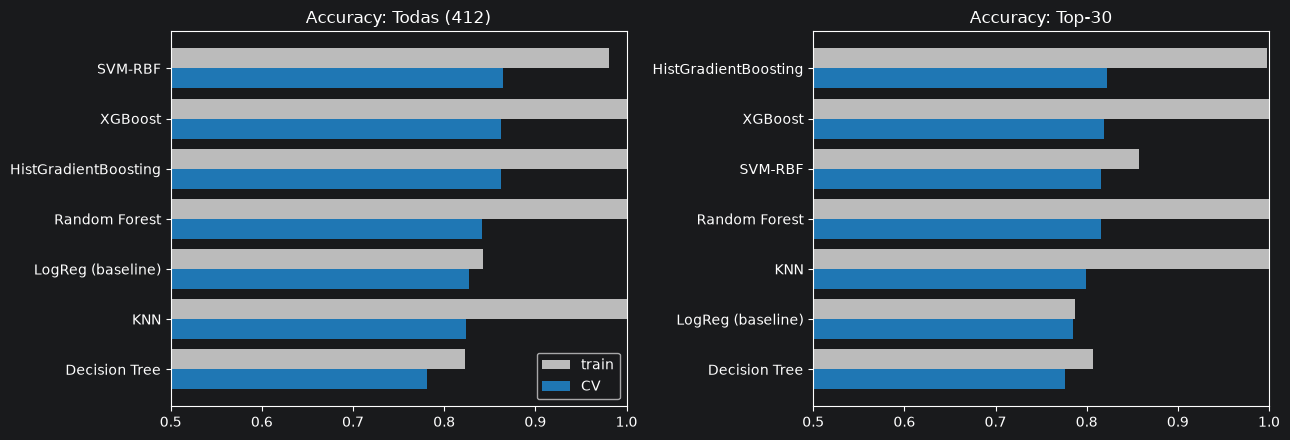

In [9]:
def train_vs_cv(raw):
    g = raw.groupby("model", sort=False)
    t = pd.DataFrame({"train_acc": g["train_acc"].mean(), "cv_acc": g["acc"].mean()})
    t["gap_acc"] = t["train_acc"] - t["cv_acc"]
    t["train_auc"], t["cv_auc"] = g["train_auc"].mean(), g["auc"].mean()
    t["gap_auc"] = t["train_auc"] - t["cv_auc"]
    t["train_recall"], t["cv_recall"] = g["train_recall_others"].mean(), g["recall_others"].mean()
    return t.sort_values("cv_acc", ascending=False).round(3)


ovf_all, ovf_top = train_vs_cv(raw_all), train_vs_cv(raw_top)
print(f"--- TODAS las features ({len(FEATS)}): train vs CV ---")
print(ovf_all.to_string(), "\n")
print(f"--- TOP-{K_FEATURES}: train vs CV ---")
print(ovf_top.to_string())
ovf_all.to_csv(OUT_DIR / "train_vs_cv_all_features.csv")
ovf_top.to_csv(OUT_DIR / f"train_vs_cv_top{K_FEATURES}.csv")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, (title, t) in zip(axs, [(f"Todas ({len(FEATS)})", ovf_all), (f"Top-{K_FEATURES}", ovf_top)]):
    t = t.drop(index="Dummy", errors="ignore")[::-1]
    yy = np.arange(len(t))
    ax.barh(yy + 0.2, t["train_acc"], 0.4, label="train", color="#bbbbbb")
    ax.barh(yy - 0.2, t["cv_acc"], 0.4, label="CV", color="#1f77b4")
    ax.set_yticks(yy, t.index); ax.set_xlim(0.5, 1.0); ax.set_title(f"Accuracy: {title}")
axs[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 5. Ablación por familias
Mismo modelo (Random Forest, sin selección) con cada familia sola y combinadas. Sirve para ver cuánto aporta
cada una y si son complementarias.

Ojo con las familias de **imagen entera** (`gcolor`, `gtex`): se calculan sobre todos los píxeles, así que pueden
captar la cámara, la iluminación o el fondo en vez de la lesión. Compara "lesión" frente a "imagen entera" y frente a "todas".

In [10]:
fam_cols = {f: [c for c in FEATS if family(c) == f] for f in ["shape", "color", "tex", "gcolor", "gtex"]}
lesion = fam_cols["shape"] + fam_cols["color"] + fam_cols["tex"]
imagen = fam_cols["gcolor"] + fam_cols["gtex"]
subsets = {"solo forma": fam_cols["shape"], "solo color": fam_cols["color"], "solo textura": fam_cols["tex"],
           "solo gcolor": fam_cols["gcolor"], "solo gtex": fam_cols["gtex"],
           "forma + color": fam_cols["shape"] + fam_cols["color"], "color + textura": fam_cols["color"] + fam_cols["tex"],
           "lesión (shape+color+tex)": lesion, "imagen entera (gcolor+gtex)": imagen,
           "todas": FEATS}
# 100 árboles bastan para comparar familias (3x más rápido; la diferencia en AUC es ~0.002)
rf = {"Random Forest": (RandomForestClassifier(n_estimators=100, min_samples_leaf=3, random_state=SEED, n_jobs=1), False)}
# todos los subconjuntos x folds en paralelo (antes iban uno detrás de otro)
abl = run_cv_many({name: Xtr[cols] for name, cols in subsets.items()}, k=None, models=rf).droplevel("model")
abl.insert(0, "n_features", [len(c) for c in subsets.values()])
print(abl.drop(columns=["_auc", "_acc"]).to_string())
abl.drop(columns=["_auc", "_acc"]).to_csv(OUT_DIR / "ablation_families.csv")

                             n_features            acc            auc        bal_acc             f1  recall_others
subset                                                                                                            
solo forma                           52  0.771 ± 0.005  0.839 ± 0.004  0.771 ± 0.005  0.766 ± 0.004  0.764 ± 0.004
solo color                           82  0.819 ± 0.005  0.897 ± 0.004  0.819 ± 0.005  0.817 ± 0.005  0.818 ± 0.011
solo textura                        104  0.772 ± 0.008  0.847 ± 0.007  0.772 ± 0.008  0.767 ± 0.008  0.761 ± 0.009
solo gcolor                          70  0.803 ± 0.007  0.882 ± 0.007  0.803 ± 0.007  0.797 ± 0.007  0.786 ± 0.010
solo gtex                           104  0.796 ± 0.005  0.873 ± 0.005  0.796 ± 0.005  0.791 ± 0.005  0.785 ± 0.007
forma + color                       134  0.818 ± 0.006  0.898 ± 0.006  0.818 ± 0.006  0.816 ± 0.007  0.819 ± 0.012
color + textura                     186  0.822 ± 0.006  0.901 ± 0.006  0.822 ± 0

## 6. Evaluación final en val
Cada modelo se entrena con **all train** (con la selección top-K dentro del pipeline) y se evalúa una sola vez en val.
Umbral de decisión por defecto (0.5). El IC del AUC se obtiene por bootstrap sobre las imágenes de val.

In [11]:
def boot_ci(y, s, n=300, seed=0):
    rng, vals = np.random.RandomState(seed), []
    for _ in range(n):
        i = rng.choice(len(y), len(y), replace=True)
        if len(np.unique(y[i])) == 2:
            vals.append(roc_auc_score(y[i], s[i]))
    return np.percentile(vals, [2.5, 97.5])


def _fit_head(model, scale, X, y):
    warnings.filterwarnings("ignore")
    return make_head(model, scale).fit(X, y)


# imputación + top-K con all train UNA vez (es la misma para todos los modelos), después los modelos en paralelo
# configuración final (todas las features o top-K) y mejor modelo: se eligen por ACCURACY en CV (nunca en val)
K_FINAL = None if res_all["_acc"].max() >= res_top["_acc"].max() else K_FEATURES
SEL_LABEL = "todas las features" if K_FINAL is None else f"top-{K_FEATURES}"
best = (res_all if K_FINAL is None else res_top).index[0]
print(f"CV accuracy: todas = {res_all['_acc'].max():.3f} | top-{K_FEATURES} = {res_top['_acc'].max():.3f} "
      f"-> configuración final: {SEL_LABEL}; mejor modelo: {best}\n")

prep = make_prep(K_FINAL, n_jobs=N_JOBS).fit(Xtr, ytr)
Xtr_s, Xva_s = prep.transform(Xtr), prep.transform(Xva)
heads = Parallel(n_jobs=N_JOBS)(delayed(_fit_head)(est, scale, Xtr_s, ytr) for est, scale in MODELS.values())

fitted, rows, scores, preds = {}, [], {}, {}
for name, head in zip(MODELS, heads):
    pipe = Pipeline(prep.steps + head.steps)          # pipeline completo ya entrenado (acepta las 420 columnas)
    s, pred = get_score(pipe, Xva), pipe.predict(Xva)
    lo, hi = boot_ci(yva, s)
    fitted[name], scores[name], preds[name] = pipe, s, pred
    rows.append({"modelo": name, "accuracy": accuracy_score(yva, pred), "AUC": roc_auc_score(yva, s), "AUC IC95%": f"[{lo:.3f}, {hi:.3f}]",
                 "bal_acc": balanced_accuracy_score(yva, pred), "F1": f1_score(yva, pred),
                 "recall_others": recall_score(yva, pred), "precision_others": precision_score(yva, pred, zero_division=0)})
val_res = pd.DataFrame(rows).set_index("modelo").sort_values("accuracy", ascending=False)
print(f"Val ({len(Xva)} imágenes), modelos con {SEL_LABEL}:\n")
print(val_res.round(3).to_string())
val_res.round(4).to_csv(OUT_DIR / "val_final.csv")

CV accuracy: todas = 0.865 | top-30 = 0.822 -> configuración final: todas las features; mejor modelo: SVM-RBF

Val (3796 imágenes), modelos con todas las features:

                      accuracy    AUC       AUC IC95%  bal_acc     F1  recall_others  precision_others
modelo                                                                                                
HistGradientBoosting     0.874  0.946  [0.939, 0.952]    0.874  0.871          0.867             0.875
XGBoost                  0.869  0.945  [0.938, 0.952]    0.869  0.866          0.861             0.871
SVM-RBF                  0.867  0.944  [0.936, 0.951]    0.867  0.865          0.861             0.869
Random Forest            0.850  0.925  [0.915, 0.933]    0.850  0.846          0.835             0.856
KNN                      0.837  0.914  [0.905, 0.924]    0.837  0.834          0.836             0.832
LogReg (baseline)        0.833  0.914  [0.904, 0.922]    0.833  0.829          0.824             0.835
Decision Tr

### 6b. Ensembles (soft voting) de los mejores modelos
Cada miembro da su probabilidad de `others`, se promedian (con pesos si se indican) y se predice `others` si la media
pasa de 0.5. Un ensemble mejora cuando sus miembros se equivocan en imágenes **distintas**: XGBoost y HGB se parecen
mucho; SVM, LogReg y Random Forest aportan más diversidad.

- Variantes (`ENSEMBLES`), con los **parámetros ajustados** en 4b. La de XGB+HGB+RF no lleva SVM y es mucho más rápida.
- El SVM de los ensembles usa `probability=True` (calibración de Platt con una CV interna): con 15.000 imágenes es
  **lento** (~5× el SVM normal). Si tarda demasiado, quita las variantes con SVM o pon `ENS_CV = False`.
- Se evalúan **por CV** (`ENS_CV = True`) igual que los demás y se añaden a la tabla de val y a las matrices de confusión.
  `best` pasa a ser el mejor por accuracy de CV contando también los ensembles.
- La columna `acc IC95%` (bootstrap en val) sirve para ver qué diferencias son ruido: con 3.796 imágenes, ±~0.011.

In [12]:
from sklearn.ensemble import VotingClassifier

ENSEMBLES = {          # nombre: (miembros, pesos o None = media simple)
    "Ens XGB+SVM": (["XGBoost", "SVM-RBF"], None),
    "Ens XGB+HGB+SVM": (["XGBoost", "HistGradientBoosting", "SVM-RBF"], None),
    "Ens XGB+SVM+LogReg": (["XGBoost", "SVM-RBF", "LogReg (baseline)"], None),
    "Ens XGB+HGB+RF": (["XGBoost", "HistGradientBoosting", "Random Forest"], None),     # sin SVM: rápido
}
ENS_CV = True          # True: CV de 5 folds de cada ensemble (para compararlos con los demás por CV)


def make_ensemble(members, weights=None):
    members = [m for m in members if m in MODELS]          # XGBoost puede no estar instalado
    ests = []
    for m in members:
        est = clone(MODELS[m][0])
        if isinstance(est, SVC):                           # soft voting necesita predict_proba
            est.set_params(probability=True, random_state=SEED)
        ests.append(("".join(ch for ch in m.lower() if ch.isalnum()), est))
    w = weights if weights is not None and len(weights) == len(ests) else None
    return VotingClassifier(ests, voting="soft", weights=w), True


def acc_ci(y, pred, n=1000, seed=0):
    rng = np.random.RandomState(seed)
    vals = [accuracy_score(y[i], pred[i]) for i in (rng.choice(len(y), len(y), replace=True) for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])


ENS_SPECS = {name: make_ensemble(*cfg) for name, cfg in ENSEMBLES.items()}
ALL_SPECS = {**MODELS, **ENS_SPECS}                        # para reentrenar el mejor, sea modelo o ensemble
ENS_MEMBERS = [m for m in MODELS if any(m in ms for ms, _ in ENSEMBLES.values())]
res_cv = res_all if K_FINAL is None else res_top
print(f"Ensembles: {list(ENS_SPECS)} | features: {SEL_LABEL}\n")

# 1) CV de 5 folds (mismos folds y features que el modelo final)
if ENS_CV:
    t_ens = run_cv(Xtr, K_FINAL, models=ENS_SPECS)
    res_cv = pd.concat([res_cv.drop(index=list(ENS_SPECS), errors="ignore"), t_ens]).sort_values("_acc", ascending=False)
    print("CV (media ± std de 5 folds): miembros y ensembles")
    print(res_cv.loc[ENS_MEMBERS + list(ENS_SPECS)].sort_values("_acc", ascending=False)
          .drop(columns=["_auc", "_acc"]).to_string(), "\n")

# 2) entrenar con todo train y evaluar en val (una vez)
heads = Parallel(n_jobs=min(N_JOBS, len(ENS_SPECS)))(
    delayed(_fit_head)(*spec, Xtr_s, ytr) for spec in ENS_SPECS.values())
rows = []
for name, head in zip(ENS_SPECS, heads):
    pipe = Pipeline(prep.steps + head.steps)
    s, pred = get_score(pipe, Xva), pipe.predict(Xva)
    lo, hi = boot_ci(yva, s)
    fitted[name], scores[name], preds[name] = pipe, s, pred
    rows.append({"modelo": name, "accuracy": accuracy_score(yva, pred), "AUC": roc_auc_score(yva, s),
                 "AUC IC95%": f"[{lo:.3f}, {hi:.3f}]", "bal_acc": balanced_accuracy_score(yva, pred),
                 "F1": f1_score(yva, pred), "recall_others": recall_score(yva, pred),
                 "precision_others": precision_score(yva, pred, zero_division=0)})
val_res = (pd.concat([val_res.drop(index=list(ENS_SPECS), errors="ignore"),
                      pd.DataFrame(rows).set_index("modelo")[val_res.columns]])
           .rename_axis("modelo").sort_values("accuracy", ascending=False))
val_res.round(4).to_csv(OUT_DIR / "val_final.csv")

cmp = val_res.loc[ENS_MEMBERS + list(ENS_SPECS), ["accuracy", "AUC", "bal_acc", "F1", "recall_others"]].copy()
cmp.insert(1, "acc IC95%", [("[{:.3f}, {:.3f}]".format(*acc_ci(yva, preds[n]))) for n in cmp.index])
if ENS_CV:
    cmp.insert(0, "cv_acc", res_cv.loc[cmp.index, "_acc"])
    cmp = cmp.sort_values("cv_acc", ascending=False)
print(f"Val ({len(Xva)} imágenes): miembros y ensembles (ordenados por accuracy de CV)\n")
print(cmp.round(3).to_string(), "\n")

# 3) el mejor según la CV, contando los ensembles (no se elige mirando val)
best = res_cv.index[0]
print(f"Mejor en CV (accuracy {res_cv['_acc'].iloc[0]:.3f}): best = {best}")

Ensembles: ['Ens XGB+SVM', 'Ens XGB+HGB+SVM', 'Ens XGB+SVM+LogReg', 'Ens XGB+HGB+RF'] | features: todas las features

CV (media ± std de 5 folds): miembros y ensembles
                                acc            auc        bal_acc             f1  recall_others
model                                                                                          
Ens XGB+SVM           0.873 ± 0.006  0.943 ± 0.005  0.873 ± 0.006  0.871 ± 0.006  0.868 ± 0.011
Ens XGB+HGB+SVM       0.871 ± 0.007  0.943 ± 0.005  0.871 ± 0.007  0.868 ± 0.007  0.864 ± 0.008
Ens XGB+SVM+LogReg    0.868 ± 0.005  0.939 ± 0.005  0.868 ± 0.005  0.866 ± 0.005  0.862 ± 0.009
SVM-RBF               0.865 ± 0.003  0.936 ± 0.004  0.865 ± 0.003  0.862 ± 0.004  0.858 ± 0.008
Ens XGB+HGB+RF        0.864 ± 0.007  0.935 ± 0.006  0.864 ± 0.007  0.861 ± 0.007  0.857 ± 0.012
XGBoost               0.862 ± 0.006  0.937 ± 0.005  0.862 ± 0.006  0.859 ± 0.006  0.856 ± 0.011
HistGradientBoosting  0.862 ± 0.008  0.935 ± 0.005  0.862 ± 0.00

### 6c. Umbral de decisión (para maximizar la accuracy)
`predict()` usa un umbral fijo: 0.5 sobre la probabilidad de `others` (o 0 sobre `decision_function` en el SVM). No
tiene por qué ser el que da más accuracy. Aquí:

1. **Puntuaciones out-of-fold** del mejor modelo (`best`): cada imagen de train la puntúa el modelo del fold en el que
   **no** se entrenó (es la CV, guardando las predicciones).
2. Se recorre el umbral y se elige el que da más accuracy sobre esas predicciones.
3. Se aplica **tal cual** en val (val no interviene en la elección).

Con clases casi balanceadas (49 % others) lo normal es que el umbral óptimo quede cerca del de por defecto y la mejora
sea pequeña: si en val no mejora, quédate con el de por defecto. El umbral se guarda en `OUT_DIR/decision_threshold.json`
y se usa con el modelo final para el test (sección 9).

Modelo: Ens XGB+SVM
CV out-of-fold: accuracy 0.8734 (umbral 0.5) -> 0.8738 (umbral 0.542)

Val (3796 imágenes), Ens XGB+SVM:

                   accuracy       acc IC95%  bal_acc      F1  recall_others  precision_others
umbral                                                                                       
por defecto (0.5)    0.8778  [0.867, 0.888]   0.8776  0.8750         0.8708            0.8793
ajustado (0.542)     0.8757  [0.865, 0.886]   0.8753  0.8712         0.8563            0.8867


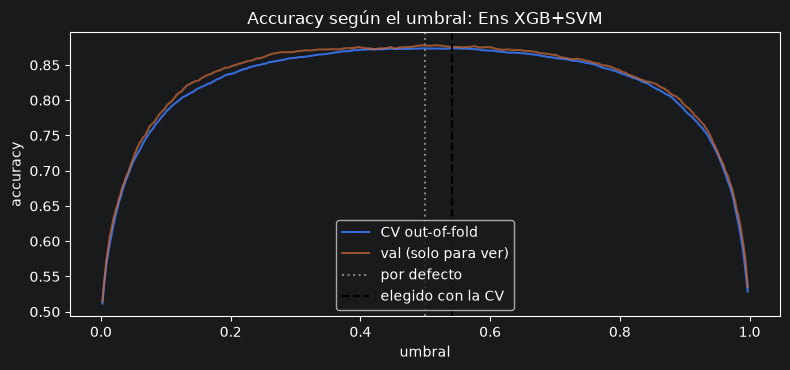

81

In [13]:
TUNE_THRESHOLD = True


def _oof_fold(spec, X, y, a, b):
    warnings.filterwarnings("ignore")
    Xa, Xb = _prep_fold(X, y, a, b, K_FINAL)
    m = make_head(*spec).fit(Xa, y[a])
    return b, get_score(m, Xb)


def oof_scores(spec):
    """Puntuaciones out-of-fold (n_train,) con los mismos folds que la CV."""
    X = np.asarray(Xtr, dtype=np.float64)
    folds = list(skf.split(np.zeros(len(ytr)), ytr))
    out = Parallel(n_jobs=min(N_JOBS, len(folds)))(delayed(_oof_fold)(spec, X, ytr, a, b) for a, b in folds)
    s = np.zeros(len(ytr))
    for b, sb in out:
        s[b] = sb
    return s


THR_DEFAULT = 0.5 if hasattr(fitted[best], "predict_proba") else 0.0      # el que usa predict()
THRESHOLD = THR_DEFAULT
if TUNE_THRESHOLD:
    s_oof = oof_scores(ALL_SPECS[best])
    grid = np.unique(np.quantile(s_oof, np.linspace(0.02, 0.98, 481)))
    accs = np.array([accuracy_score(ytr, (s_oof >= t).astype(int)) for t in grid])
    THRESHOLD = float(grid[accs.argmax()])
    acc_def = accuracy_score(ytr, (s_oof >= THR_DEFAULT).astype(int))
    print(f"Modelo: {best}")
    print(f"CV out-of-fold: accuracy {acc_def:.4f} (umbral {THR_DEFAULT}) -> {accs.max():.4f} (umbral {THRESHOLD:.3f})\n")

    rows = []
    for lab, t in [(f"por defecto ({THR_DEFAULT})", THR_DEFAULT), (f"ajustado ({THRESHOLD:.3f})", THRESHOLD)]:
        pr = (scores[best] >= t).astype(int)
        lo, hi = acc_ci(yva, pr)
        rows.append({"umbral": lab, "accuracy": accuracy_score(yva, pr), "acc IC95%": f"[{lo:.3f}, {hi:.3f}]",
                     "bal_acc": balanced_accuracy_score(yva, pr), "F1": f1_score(yva, pr),
                     "recall_others": recall_score(yva, pr), "precision_others": precision_score(yva, pr, zero_division=0)})
    thr_res = pd.DataFrame(rows).set_index("umbral")
    print(f"Val ({len(Xva)} imágenes), {best}:\n")
    print(thr_res.round(4).to_string())
    thr_res.round(4).to_csv(OUT_DIR / "val_threshold.csv")

    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.plot(grid, accs, label="CV out-of-fold")
    ax.plot(grid, [accuracy_score(yva, (scores[best] >= t).astype(int)) for t in grid], alpha=0.7, label="val (solo para ver)")
    ax.axvline(THR_DEFAULT, color="gray", ls=":", label="por defecto")
    ax.axvline(THRESHOLD, color="k", ls="--", label="elegido con la CV")
    ax.set(xlabel="umbral", ylabel="accuracy", title=f"Accuracy según el umbral: {best}")
    ax.legend(); plt.tight_layout(); plt.show()

(OUT_DIR / "decision_threshold.json").write_text(
    json.dumps({"model": best, "threshold": THRESHOLD, "default": THR_DEFAULT}, indent=2), encoding="utf-8")

Mejor modelo en CV: Ens XGB+SVM


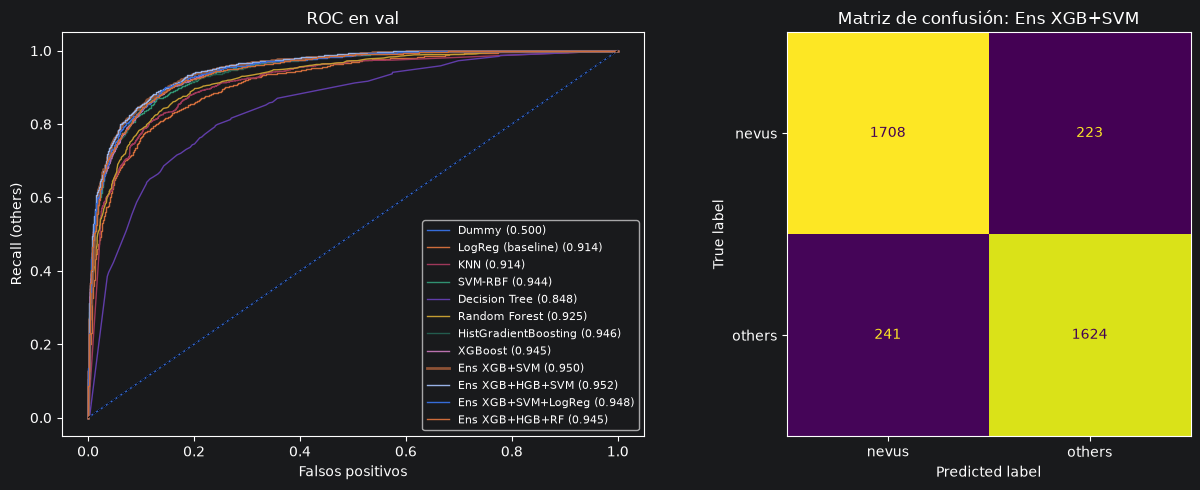

In [14]:
# best ya elegido arriba: mejor modelo según accuracy en CV (no según val)
print("Mejor modelo en CV:", best)

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(yva, s)
    axs[0].plot(fpr, tpr, lw=2 if name == best else 1, label=f"{name} ({roc_auc_score(yva, s):.3f})")
axs[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axs[0].set(xlabel="Falsos positivos", ylabel="Recall (others)", title="ROC en val"); axs[0].legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(yva, fitted[best].predict(Xva), display_labels=["nevus", "others"],
                                        ax=axs[1], colorbar=False)
axs[1].set_title(f"Matriz de confusión: {best}")
plt.tight_layout(); plt.show()

### Matriz de confusión de todos los modelos (val)

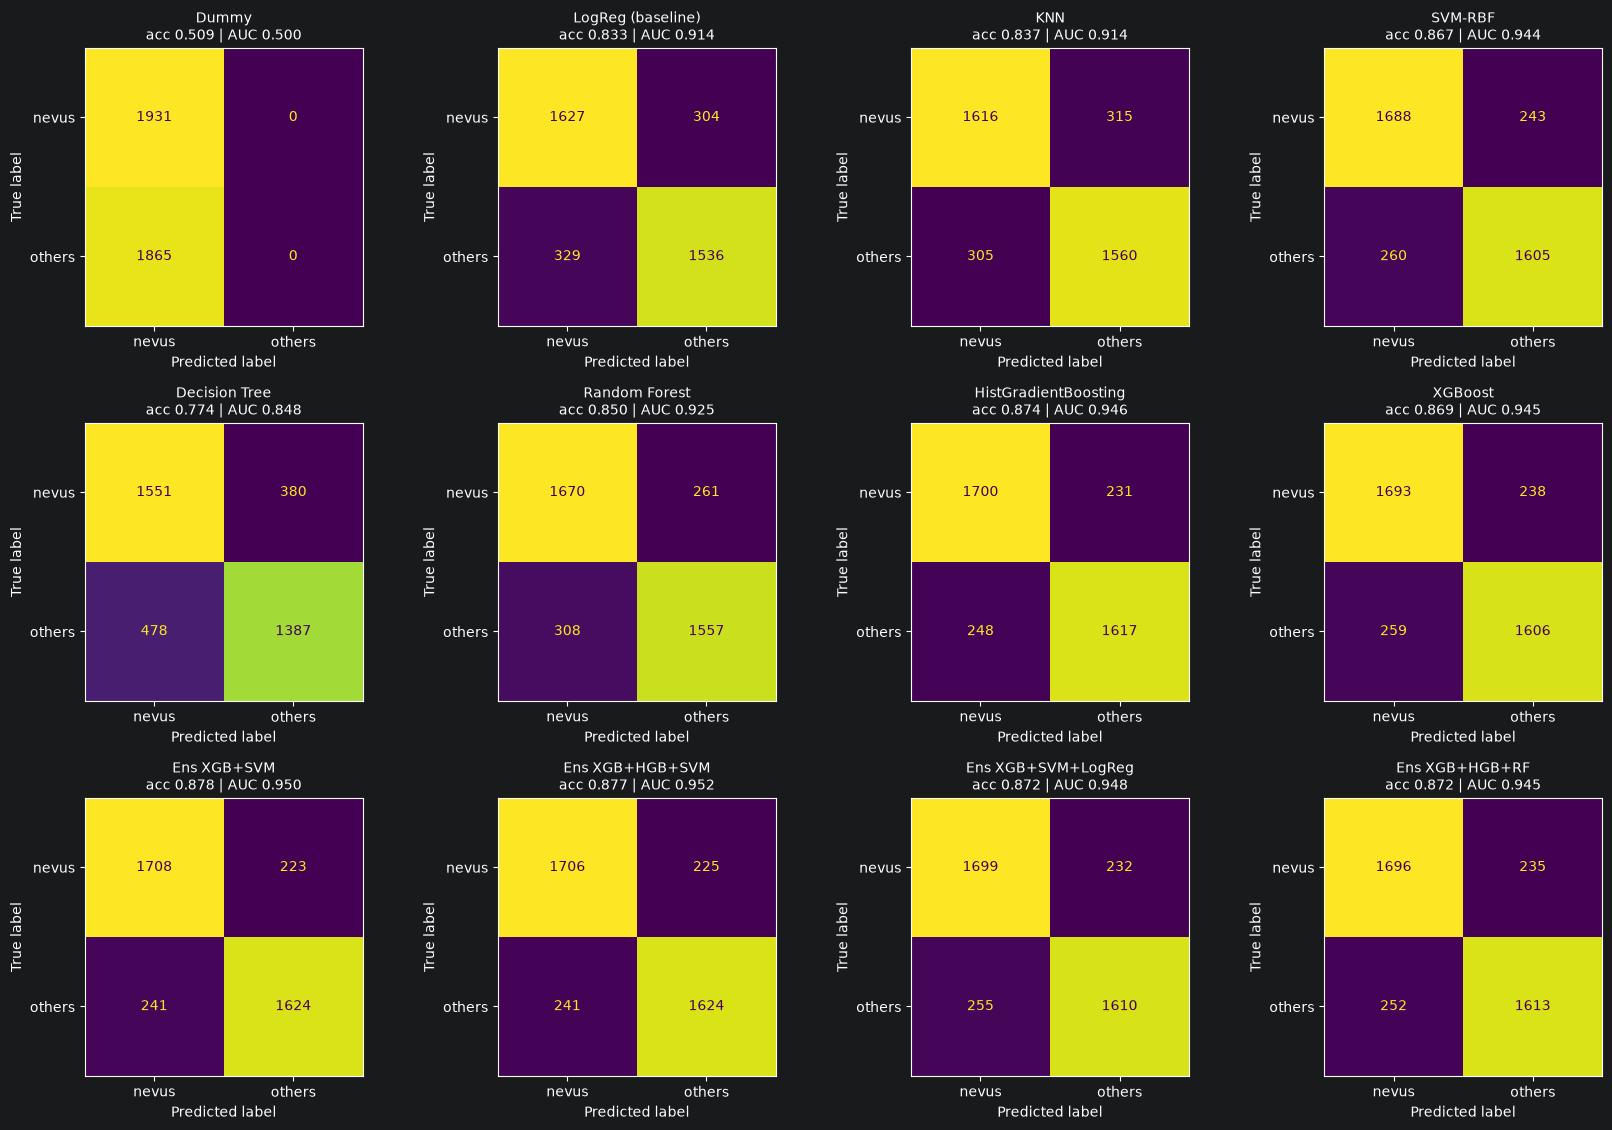

In [15]:
names = list(fitted)
nc = 4
nr = int(np.ceil(len(names) / nc))
fig, axs = plt.subplots(nr, nc, figsize=(4.2 * nc, 3.8 * nr), squeeze=False)
for ax, name in zip(axs.ravel(), names):
    ConfusionMatrixDisplay.from_predictions(yva, preds[name], display_labels=["nevus", "others"],
                                            ax=ax, colorbar=False)
    ax.set_title(f"{name}\nacc {val_res.loc[name, 'accuracy']:.3f} | AUC {val_res.loc[name, 'AUC']:.3f}", fontsize=10)
for ax in axs.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### Guardar los modelos
Se guarda cada modelo final (entrenado con todo train) en `ml_results_completes/models/` como un `.joblib` con el **pipeline completo**
(imputación → selección → escalado → modelo), más una copia del mejor como `best_model.joblib` y un `models_info.json`
con la lista de features (en orden), las etiquetas, las métricas en val y las versiones de las librerías.
(`*.joblib` está en el `.gitignore`: no se suben a GitHub.)

Para usarlos después (por ejemplo con las features del test), hacen falta **las mismas versiones** de sklearn / xgboost:
```python
import json, joblib, pandas as pd
d = ROOT / "ml" / "ml_results_completes" / "models"
info = json.load(open(d / "models_info.json", encoding="utf-8"))
model = joblib.load(d / "best_model.joblib")
X_test = pd.read_csv("features_test.csv")[info["features"]]     # mismas columnas, mismo orden
pred = model.predict(X_test)                                    # 0 = nevus, 1 = others; model.predict_proba(X_test)[:, 1] = probabilidad de others
```

In [16]:
TASK = "binary"
LABELS = {0: "nevus", 1: "others"}
SELECTION = "ninguna (todas las features)" if K_FINAL is None else f"top-{K_FEATURES} (Extra Trees, SelectFromModel)"

import json
import platform
from datetime import datetime

import joblib
import sklearn

MODEL_DIR = OUT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
slug = lambda s: "".join(ch if ch.isalnum() else "_" for ch in s).strip("_").lower()

# cada archivo es el pipeline COMPLETO ya entrenado con all train:
# imputación -> [selección top-K] -> [escalado] -> modelo. Recibe las features crudas (FEATS, en ese orden).
saved = {}
for name, pipe in fitted.items():
    if name == "Dummy":
        continue
    path = MODEL_DIR / f"{slug(name)}.joblib"
    joblib.dump(pipe, path, compress=3)
    saved[name] = path.name
joblib.dump(fitted[best], MODEL_DIR / "best_model.joblib", compress=3)

# comprobación: el modelo recargado predice exactamente lo mismo en val
assert (joblib.load(MODEL_DIR / "best_model.joblib").predict(Xva) == preds[best]).all()

try:
    import xgboost
    xgb_version = xgboost.__version__
except Exception:
    xgb_version = None

info = {
    "task": TASK,
    "created": datetime.now().isoformat(timespec="seconds"),
    "best_model": best,
    "files": {**saved, "best": "best_model.joblib"},
    "labels": LABELS,
    "feature_selection": SELECTION,
    "n_features_in": len(FEATS),
    "features": FEATS,                                   # columnas de entrada, en este orden
    "train_csv": str(TRAIN_CSV),
    "val_metrics": val_res.reset_index().to_dict(orient="records"),
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__, "xgboost": xgb_version,
                 "numpy": np.__version__, "pandas": pd.__version__},
}
(MODEL_DIR / "models_info.json").write_text(json.dumps(info, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

print(f"Modelos guardados en {MODEL_DIR}  (mejor: {best} -> best_model.joblib)\n")
for f in sorted(MODEL_DIR.glob("*")):
    print(f"  {f.name:<35s} {f.stat().st_size / 1e6:7.1f} MB")

Modelos guardados en C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG\ml\ml_results_binary_gridsearch\models  (mejor: Ens XGB+SVM -> best_model.joblib)

  best_model.joblib                      21.9 MB
  decision_tree.joblib                    0.0 MB
  ens_xgb_hgb_rf.joblib                  15.8 MB
  ens_xgb_hgb_svm.joblib                 23.5 MB
  ens_xgb_svm.joblib                     21.9 MB
  ens_xgb_svm_logreg.joblib              21.9 MB
  histgradientboosting.joblib             1.5 MB
  knn.joblib                             45.9 MB
  logreg__baseline.joblib                 0.5 MB
  models_info.json                        0.0 MB
  random_forest.joblib                   12.7 MB
  svm_rbf.joblib                         21.0 MB
  xgboost.joblib                          0.9 MB


### ¿Qué features usa realmente el mejor modelo?
Importancia por permutación en val (cuánto cae el AUC al barajar cada feature). Solo se permutan las top-K del selector
(las demás pesan ~0), así va mucho más rápido.
Sirve también para vigilar que no dominen features raras (por ejemplo del color global, `gcolor_`/`gtex_`) que podrían
delatar la cámara y no la lesión.

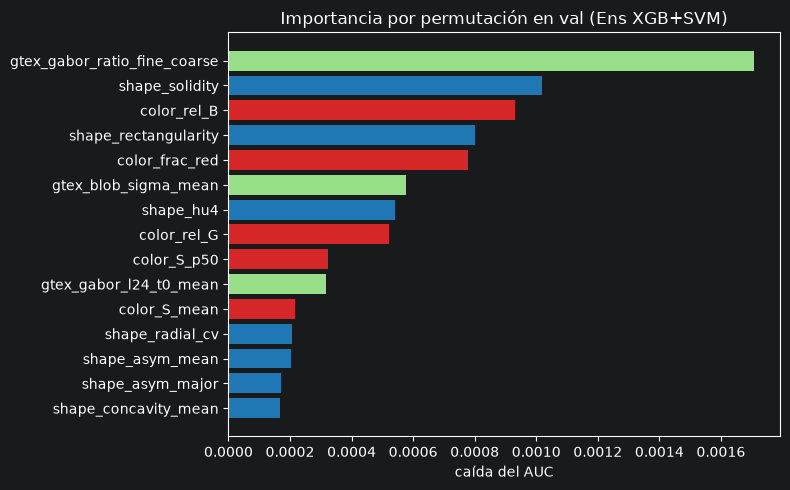

In [17]:
pipe = fitted[best]
if "sel" in pipe.named_steps:
    sel, skip = pipe.named_steps["sel"].get_support(), 2
else:                                                             # sin selección: se usan todas las features
    sel, skip = np.ones(len(FEATS), dtype=bool), 1
names_in = np.array(FEATS)[sel]
Xin = pipe.named_steps["imp"].transform(Xva)[:, sel]
head = pipe[skip:]
cand = [i for i, f in enumerate(names_in) if f in set(SELECTED)]  # solo las top-K del selector (las demás pesan ~0)
base_auc = roc_auc_score(yva, get_score(head, Xin))


def _perm(j, reps=3):
    rng, drops = np.random.RandomState(SEED + j), []
    for _ in range(reps):
        Xp = Xin.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
        drops.append(base_auc - roc_auc_score(yva, get_score(head, Xp)))
    return np.mean(drops)


pi = pd.Series(Parallel(n_jobs=N_JOBS)(delayed(_perm)(j) for j in cand), index=names_in[cand])
pi = pi.sort_values(ascending=False).head(15)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(pi.index, pi.values, color=[FAM_COLOR[family(c)] for c in pi.index])
plt.title(f"Importancia por permutación en val ({best})")
plt.xlabel("caída del AUC"); plt.tight_layout(); plt.show()

In [18]:
man_path = ROOT / "processed" / "manifest.csv"
if man_path.exists():
    man = pd.read_csv(man_path).set_index("name")
    cols = ["orig_h", "orig_w"]
    m_tr, m_va = man.reindex(tr["name"])[cols], man.reindex(va["name"])[cols]
    g = HistGradientBoostingClassifier(random_state=SEED).fit(m_tr, ytr)
    print("AUC solo con el tamaño original:", roc_auc_score(yva, g.predict_proba(m_va)[:, 1]))
else:
    print(f"No encuentro {man_path}: se omite el control de resolución.")

No encuentro C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG\processed\manifest.csv: se omite el control de resolución.


In [19]:
pred = fitted[best].predict(Xva)
tmp = va[["subtype"]].assign(acierto=(pred == yva))
print(tmp.groupby("subtype")["acierto"].agg(["mean", "size"]).round(3))

          mean  size
subtype             
ack      0.969   130
bcc      0.972   498
bkl      0.830   393
def      0.771    35
mel      0.798   678
nev      0.885  1931
scc      0.957    94
vac      0.811    37


In [20]:
if man_path.exists():
    sz = man.reindex(va["name"])[["orig_h", "orig_w"]].reset_index(drop=True)
    va_sz = va[["name", "class"]].reset_index(drop=True).join(sz)
    va_sz["res"] = va_sz["orig_w"].astype(str) + "x" + va_sz["orig_h"].astype(str)

    print(pd.crosstab(va_sz["res"], va_sz["class"]).sort_values("nevus", ascending=False).head(10))

    s, rows = scores[best], []
    for res, g in va_sz.groupby("res"):
        y = yva[g.index]
        if len(g) >= 30 and 0 < y.mean() < 1:
            rows.append((res, len(g), round(y.mean(), 2), roc_auc_score(y, s[g.index])))
    print(pd.DataFrame(rows, columns=["res", "n", "frac_others", "AUC"]).round(3))

In [21]:
# AUC solo melanoma vs nevus
m = va["subtype"].isin(["mel", "nev"]).values
print("AUC mel vs nev:", roc_auc_score(yva[m], scores[best][m]))

# sensibilidad de others a especificidad fija de nevus
fpr, tpr, _ = roc_curve(yva, scores[best])
for sp in [0.80, 0.90, 0.95]:
    print(f"especificidad {sp:.0%}: sensibilidad {tpr[np.searchsorted(fpr, 1 - sp, side='right') - 1]:.3f}")

AUC mel vs nev: 0.9271779031452363
especificidad 80%: sensibilidad 0.937
especificidad 90%: sensibilidad 0.850
especificidad 95%: sensibilidad 0.762


## 9. Modelo final para el test: reentrenar con train + val
Una vez decidido todo con la CV (parámetros, features, modelo o ensemble, umbral) y comprobado en val, se reentrena el
**mismo** pipeline con **train + val** (25 % más de datos). Val ya no puede evaluar este modelo (lo ha visto), así que su
rendimiento esperado es el de val o algo mejor.

Se guarda en `OUT_DIR/models/final_model_trainval.joblib` junto con `final_model_trainval.json` (features en orden,
etiquetas y umbral). Para predecir el test:

```python
import json, joblib, numpy as np, pandas as pd
d = ROOT / "ml" / "ml_results_binary_gridsearch" / "models"
info = json.load(open(d / "final_model_trainval.json", encoding="utf-8"))
model = joblib.load(d / "final_model_trainval.joblib")
X_test = pd.read_csv("features_test.csv")[info["features"]]          # mismas columnas, mismo orden
s = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_test)
pred = (s >= info["threshold"]).astype(int)                          # 0 = nevus, 1 = others
```

In [22]:
import joblib

FIT_TRAINVAL = True

if FIT_TRAINVAL:
    Xall = pd.concat([Xtr, Xva], ignore_index=True)
    yall = np.r_[ytr, yva]
    prep_all = make_prep(K_FINAL, n_jobs=N_JOBS).fit(Xall, yall)
    head_all = _fit_head(*ALL_SPECS[best], prep_all.transform(Xall), yall)
    final_pipe = Pipeline(prep_all.steps + head_all.steps)

    MODEL_DIR = OUT_DIR / "models"
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    joblib.dump(final_pipe, MODEL_DIR / "final_model_trainval.joblib", compress=3)
    final_info = {"model": best, "trained_on": f"train + val ({len(yall)} imágenes)", "feature_selection": SEL_LABEL,
                  "params": best_params, "threshold": THRESHOLD, "labels": {0: "nevus", 1: "others"},
                  "features": FEATS, "cv_accuracy": float(res_cv.loc[best, "_acc"]),
                  "val_accuracy": float(val_res.loc[best, "accuracy"])}
    (MODEL_DIR / "final_model_trainval.json").write_text(json.dumps(final_info, indent=2, ensure_ascii=False, default=str),
                                                         encoding="utf-8")
    print(f"Modelo final: {best} | entrenado con {len(yall)} imágenes (others = {yall.mean():.1%}) | umbral {THRESHOLD:.3f}")
    print(f"guardado en {MODEL_DIR / 'final_model_trainval.joblib'}")

Modelo final: Ens XGB+SVM | entrenado con 18991 imágenes (others = 49.2%) | umbral 0.542
guardado en C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG\ml\ml_results_binary_gridsearch\models\final_model_trainval.joblib
